[Open in Colab](https://colab.research.google.com/github/loem-ms/programming-for-information-systems-site/blob/main/content/downloads/Week_06.ipynb) · [Download notebook](/downloads/Week_06.ipynb) · [Optional ZIP](/downloads/Week_06.zip)

**Before editing:** File → Save a copy in Drive.


# Week 06 · Classes, instances and methods


(week-06-start)=
[Session 1](#week-06-session-1) · [Session 2](#week-06-session-2) · [Session 3](#week-06-project-studio)



(week-06-session-1)=
## Session 1 · Python foundations


### A class and an instance

A class defines a kind of object. Calling it creates an instance with its own data. pass marks an empty body in this first example.

```python
class Rectangle: pass
first = Rectangle()
```


### Attributes

An attribute stores data on one instance. It resembles a named field in a dictionary.

```python
class Rectangle: pass
first = Rectangle()
first.width = 3
first.height = 4
```


### Initialization

__init__ receives the new instance as self. The right width is a parameter; self.width stores it on that instance.

```python
class Rectangle:
    def __init__(self, width): self.width = width
```


### Methods

A method is a function associated with the class. self identifies the instance. The full example below defines the area method.

```python
class Rectangle:
    def area(self): return self.width * self.height
```


### Calling a method

Parentheses call a method. Python supplies self automatically. Reading first.area without parentheses only refers to the method.

```python
class Rectangle:
    def area(self): return 3 * 4
print(Rectangle().area())  # 12
```


### Independent objects

Two instances have separate attributes. Changing one does not change the other. Objects disappear when the process ends unless saved explicitly.

```python
class Rectangle: pass
first = Rectangle()
second = Rectangle()
first.width = 3
second.width = 5
```


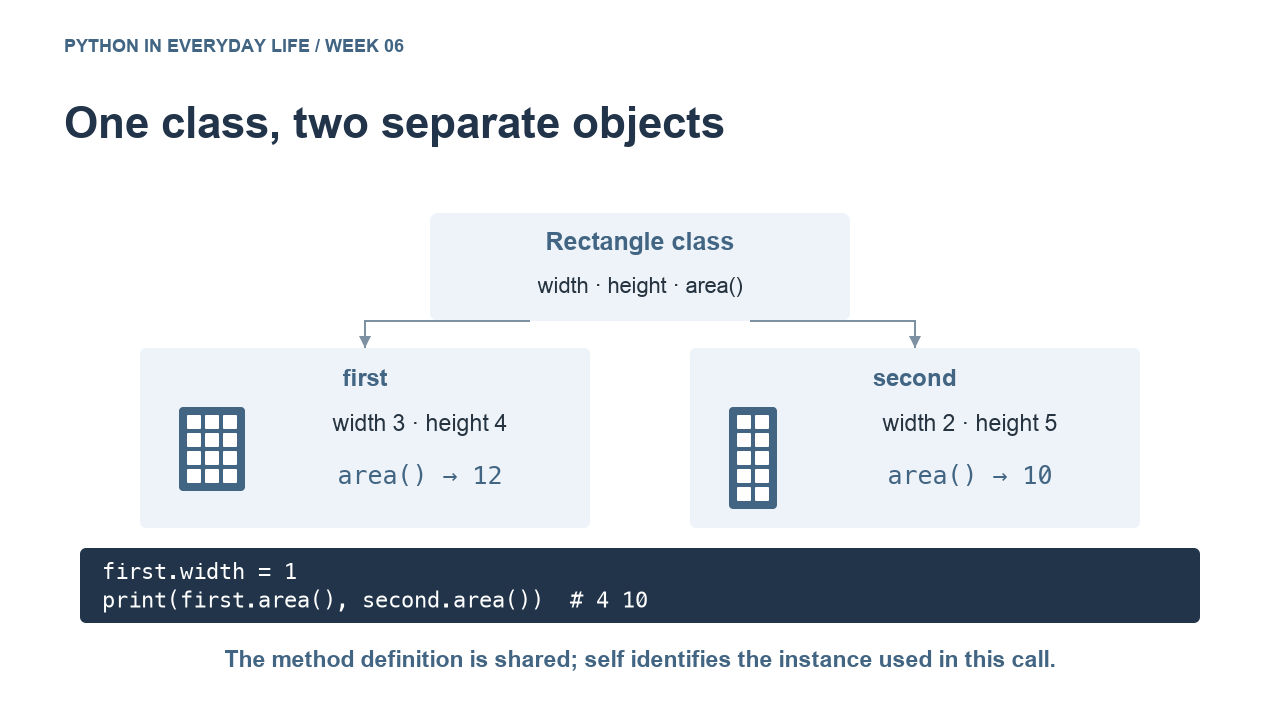


### Stored rows

SQLite queries use a separate parameter tuple. A one-item tuple needs a comma. fetchone returns a row or None; a stored zero differs from a missing row.

```python
record_id = "A"
parameters = (record_id,)  # one-item tuple for a query
```


### Example 1 · Construct one object and read attributes

class defines a type; calling it creates one instance. __init__ stores the supplied value on that instance. self refers to the instance being initialized. Predict A. No method calculation or database is involved yet.


In [ ]:
class Label:
    def __init__(self, text):
        self.text = text

label = Label("A")
print(label.text)


### Example 2 · Call a method and use its returned value

A method is a function on an object. The call counter.next_value() supplies self automatically. Parentheses run the method; return sends data to the caller. Predict 4, then the unchanged stored value 3. This method calculates without changing the stored value.


In [ ]:
class Counter:
    def __init__(self, value):
        self.value = value

    def next_value(self):
        return self.value + 1

counter = Counter(3)
print(counter.next_value())
print(counter.value)


### Example 3 · Separate instances have separate attributes

Calling the class twice creates two objects. Assigning first.value changes only first. Predict 9 and 2. Neither object is automatically written to a file or database.


In [ ]:
class Counter:
    def __init__(self, value):
        self.value = value

first = Counter(1)
second = Counter(2)
first.value = 9
print(first.value, second.value)


### Combined example


In [ ]:
class Rectangle:
    def __init__(self, width, height):
        self.width = width
        self.height = height

    def area(self):
        return self.width * self.height

first = Rectangle(3, 4)
second = Rectangle(2, 5)
print(first.area(), second.area())
first.width = 1
print(first.area(), second.area())
assert first.area() == 4
assert second.area() == 10


Predict 12 10, then 4 10. Each call reads the attributes of its own instance. Changing first.width affects only first. The returned area can be tested independently of printing.

### Research 4 exchange · during Session 1

Share your already prepared Research 4 response about **how programs keep data**. Compare one saved fact, its identifier and what should remain unchanged after a later correction. Keep your source, one question or useful feedback, and your own response. This closes the previously assigned research task; it adds no new assignment.

**My feedback and next step:** …



(week-06-session-2)=
## Session 2 · Hands-on practice

(week-06-practice-week-06)=
Five exercises: P1–P3 are core; P4–P5 are optional. Record an expected result, observed result and explanation for each completed exercise.


### P1 · Store fields on an object

**Core**

Easy. Write a class named BatchNote whose constructor takes batch_id and containers and stores both on self. Create T01 with 4 containers and print both attributes. Hint: use __init__; the right side is a parameter and self names this instance. Write the code without copying the full demo.

In [ ]:
# Write your code here. Predict before running.


**Expected:** …  **Observed:** …  **Explanation:** …


### P2 · Write and call a method

**Core**

Easy. In your BatchNote class, write has_containers(self), returning whether its count is greater than zero. Create separate objects with 0 and 3. Predict False and True, then write assertions. Hint: return a comparison; call the method with parentheses. Changing one object must not change the other.

In [ ]:
# Write your code here. Predict before running.


**Expected:** …  **Observed:** …  **Explanation:** …


### P3 · Write a planning-line class

**Core**

Write the constructor and planned_portions method from the field contract, then create two objects yourself. Use T11 with 2 portions × 3 containers and T12 with 4 × 2. Write assertions for 6 and 8. Change only T11 to 1 container and check both results again. Use the demo only as a syntax reference.

In [ ]:
class PracticeLine:
    # Write __init__(self, batch_id, portions_per_container, containers).
    # Store each field and write planned_portions(self).
    pass

# Create two objects and write your assertions here.


**Expected:** …  **Observed:** …  **Explanation:** …


### P4 · Write a safe lookup

**Optional**

Optional for learners who finish the core. Use the supplied isolated database. Write lookup_planned(db, plan_id): run a parameterized SELECT, fetch one row, return None if missing and the integer otherwise. Do not change the setup. Check P11 → 6, P12 → 0, and unknown → None. Explain why if not row[0] would confuse zero with absence.

In [ ]:
import sqlite3
practice_db = sqlite3.connect(":memory:")
practice_db.execute("CREATE TABLE practice_plans(plan_id TEXT PRIMARY KEY, planned INTEGER)")
with practice_db:
    practice_db.executemany("INSERT INTO practice_plans VALUES (?, ?)", [("P11", 6), ("P12", 0)])

def lookup_planned(db, plan_id):
    # Write the query, missing-row branch and return.
    raise NotImplementedError

# Write three independent assertions here.


**Expected:** …  **Observed:** …  **Explanation:** …


### P5 · Write snapshot evidence

**Optional**

Optional for learners who finish the core. Use your class and the supplied database setup. Write an INSERT inside with practice_db to save a new plan P13 with 3 × 4 planned portions. Then change the object to 1 container. Write SELECT and assertions proving the stored value is still 12 while the method returns 3. You write the save and check code. This isolated exercise does not yet prove file persistence. Explain to a peer.

In [ ]:
import sqlite3
practice_db = sqlite3.connect(":memory:")
practice_db.execute("CREATE TABLE practice_plans(plan_id TEXT PRIMARY KEY, planned INTEGER)")
with practice_db:
    practice_db.executemany("INSERT INTO practice_plans VALUES (?, ?)", [("P11", 6), ("P12", 0)])

# Reuse your PracticeLine definition from task 1.
# Create a line, save P13, change the line and query the saved value.
# Write assertions for both the current calculation and stored snapshot.


**Expected:** …  **Observed:** …  **Explanation:** …


Optional after the core: use a temporary SQLite file, save one snapshot, close and reopen it, then verify the same value. Use the Session 3 path example; do not add a new schema.


(week-06-project-studio)=
## Session 3 · Project studio


### Project files

Run this collapsed cell once, and again after a runtime restart. No ZIP, upload or network download is needed. Existing support files are preserved. Save created or edited files separately.


In [ ]:
# @title Prepare the course files (run after each runtime restart)
# Supplied programs, starter policy, CSV fixtures and diagrams are embedded here.
# This cell uses only Python's standard library. It makes no network request.
import base64 as _course_base64
import hashlib as _course_hashlib
import json as _course_json
import os as _course_os
from pathlib import Path as _CoursePath
import zlib as _course_zlib

_course_payload = '...'
_course_raw = _course_zlib.decompress(_course_base64.b64decode(_course_payload))
if _course_hashlib.sha256(_course_raw).hexdigest() != 'e5ead1def83f8f7ae989d29d6808b835536587c212f2bf03ada2c384018b21cc':
    raise ValueError("Embedded course files are damaged; get a fresh notebook.")
_course_files = _course_json.loads(_course_raw)
_course_key = 'week_06_e5ead1def83f'
_course_roots = globals().setdefault("_course_workspace_roots", {})
if _course_key in _course_roots:
    _course_root = _CoursePath(_course_roots[_course_key])
elif all((_CoursePath.cwd() / _name).is_file() for _name in _course_files):
    # A complete extracted offline pack can be used in place.
    _course_root = _CoursePath.cwd()
else:
    _course_root = _CoursePath.cwd() / ".course_files" / _course_key
if _course_root.is_symlink() or any(_p.is_symlink() for _p in _course_root.parents):
    raise ValueError("Refusing a symbolic link in the course workspace")
_course_root.mkdir(parents=True, exist_ok=True)
for _name, _encoded in _course_files.items():
    _relative = _CoursePath(_name)
    if _relative.is_absolute() or ".." in _relative.parts:
        raise ValueError("Unsafe embedded support path")
    _target = _course_root / _relative
    if _target.is_symlink() or any(_p.is_symlink() for _p in _target.parents):
        raise ValueError("Refusing a symbolic link in the course workspace")
    _target.parent.mkdir(parents=True, exist_ok=True)
    if _target.exists() and not _target.is_file():
        raise ValueError("Course support path is not a regular file: " + str(_target))
    if not _target.exists():
        with _target.open("xb") as _output:
            _output.write(_course_base64.b64decode(_encoded))
_course_workspace_roots[_course_key] = str(_course_root.resolve())
_course_os.chdir(_course_root)
print("Course files ready:", _CoursePath.cwd())
print("Existing files were kept. Rerunning setup never replaces your edits.")
print("Save your notebook and download created/edited files before the runtime ends.")


### The people’s task this week

**Someone needs help:** The next volunteer needs to find the plan tomorrow.

**Your small part:** Save a plan and retrieve it after closing and reopening the database.

![Week 6: the person’s need, your task, and the useful result.](assets/diagrams/course_week_06.svg)

**Picture one example:** Save → close → reopen → find the same plan.

**A useful result:** The next volunteer can find the same saved facts.

Use the supplied starting files and the task instructions below. The diagram explains the purpose; it adds no separate assignment.

**Final-project connection:** The final preview separates a small planning function from the supplied storage engine. The optional form does not save or reserve anything. Use this week's examples to understand stored records rather than rebuilding the engine.


In [ ]:
# @title Show this lesson’s embedded diagram(s)
try:
    from IPython.display import SVG, display
except ImportError:
    print("Diagrams are in assets/diagrams; Jupyter or Colab displays them below.")
else:
    display(SVG(filename='assets/diagrams/course_week_06.svg'))


### Read the supplied SQL before using it

SQL is a second language for working with database tables. The Python code sends SQL text to SQLite through execute. You are not expected to design the supplied schema from scratch.

- CREATE TABLE names a table and its columns; PRIMARY KEY identifies a record uniquely.
- INSERT INTO adds a row. Match the values to the named columns.
- SELECT chooses columns; FROM names the table; WHERE selects matching rows. UPDATE changes a stored field.
- Use ? placeholders and a separate tuple for values. A one-value tuple needs a comma: (plan_id,).
- A JOIN connects rows by a shared identifier. A saved plan line keeps its own unit snapshot, even if the current offer row changes.
- commit saves pending changes; close ends the connection. Reopen the same file path to check persistence. An in-memory database cannot survive closing.

Follow the small examples below before the plan task. Start with one inserted row and one retrieved result, then extend to the supplied plan and line tables. No class-to-database mapping is automatic.


### Example 1 · Write and read one row before linking tables

This isolated database demonstrates only table creation, a parameterized insert and a parameterized lookup. A placeholder represents a value. fetchone returns a tuple, so row[0] reads its first field. Predict 4. The project then adds identifiers and line relationships.


In [ ]:
import sqlite3
example_db = sqlite3.connect(":memory:")
try:
    example_db.execute("CREATE TABLE scores(name TEXT PRIMARY KEY, points INTEGER)")
    example_db.execute("INSERT INTO scores(name, points) VALUES (?, ?)", ("A", 4))
    example_db.commit()
    row = example_db.execute("SELECT points FROM scores WHERE name = ?", ("A",)).fetchone()
    print(row[0])
    assert row == (4,)
finally:
    example_db.close()


### Project application reference examples

These saved lesson examples support the project tasks below. Run the one you need; Python core practice is in Session 2.

**SQL parameters and a returned row**

In [ ]:
import sqlite3
db = sqlite3.connect(":memory:")
db.execute("CREATE TABLE plans(id TEXT, portions INT)")
db.execute("INSERT INTO plans VALUES (?, ?)",
           ("DEMO-P", 12))
row = db.execute("SELECT portions FROM plans WHERE id=?",
                 ("DEMO-P",)).fetchone()
assert row == (12,)
print(row)
db.close()


**File persistence: commit, close and reopen**

In [ ]:
from tempfile import TemporaryDirectory
from pathlib import Path
import sqlite3
with TemporaryDirectory() as folder:
    path = Path(folder) / "plans.sqlite"
    db = sqlite3.connect(path)
    db.execute("CREATE TABLE plans(portions INT)")
    with db: db.execute("INSERT INTO plans VALUES (12)")
    db.close()
    db = sqlite3.connect(path)
    print(db.execute("SELECT * FROM plans").fetchone())
    db.close()


**None: handle a missing query result**

In [ ]:
import sqlite3
db = sqlite3.connect(":memory:")
db.execute("CREATE TABLE plans(id TEXT, portions INT)")
row = db.execute("SELECT portions FROM plans WHERE id=?",
                 ("unknown",)).fetchone()
if row is None:
    print("Plan not found")
else:
    print(row[0])
db.close()


### Project context

In this fictional case, a stored plan preserves the declared units and human review decision. A reservation is not a collection or delivery.



### Preserve the plan that the coordinator actually saw

Campus Food Rescue can read donor claims and calculate planning totals. The coordinator now asks for yesterday's plan after the program has closed. A later correction to a batch's portion unit must not silently rewrite that plan.

This week stores a **pickup plan** with status `planning`. It is not an operational reservation: no available containers are consumed, and nothing is declared collected or delivered. Next week adds atomic approved reservations.

Learn class/instance/method vocabulary, explicit SQL relationships, historical unit snapshots, file paths and persistence across processes. Use [objects](https://loem-ms.github.io/programming-for-information-systems-site/content/learning-materials/python-basics/#python-basics-b18), [SQLite](https://loem-ms.github.io/programming-for-information-systems-site/content/learning-materials/python-basics/#python-basics-b13) and [paths](https://loem-ms.github.io/programming-for-information-systems-site/content/learning-materials/python-basics/#python-basics-b16).

![Batch and plan identities connect to line records with saved portion units.](assets/diagrams/w06_records.svg)

In [ ]:
# @title Show this lesson’s embedded diagram(s)
try:
    from IPython.display import SVG, display
except ImportError:
    print("Diagrams are in assets/diagrams; Jupyter or Colab displays them below.")
else:
    display(SVG(filename='assets/diagrams/w06_records.svg'))


### Sketch the planning records

Use Research Assignment 4 examples and paper plans to propose batch, pickup-plan and plan-line fields. Compare a Python object with a persistent record.

### Model time as well as identity

One batch can appear in many plans; one plan contains several lines. Store a line number because the same batch might appear twice. A plan line stores the **portions-per-container snapshot** that supported its estimate. The current batch declaration can then change without changing the historical calculation.

| Fact | Record | Why |
|---|---|---|
| Current batch description and unit | offer_batches | Current planning reference |
| Plan identity and `planning` status | pickup_plans | Find a document and explain its authority |
| Containers and historical unit | plan_lines | Reconstruct the original estimate |
| Unnecessary recipient personal details | Omit from this teaching case | Not needed for the stated lookup |

These records describe a plan. A human review flag alone is not an event, and saving a plan does not consume availability.

### Save and retrieve a plan

Insert a plan and two lines, then commit, close and reopen the same file. Compare the retrieved historical estimate with a hand calculation.


(week-06-project-task)=
### Student lab · implement the missing behavior

Save plan P11 for two Q11 containers and one Q12 container, with status planning. Preserve each line's unit snapshot. Reconnect, retrieve it, and then change Q11's current unit from 3 to 4. Compare the historical estimate with a recalculation using current units. Check an unknown plan ID and prove availability was not consumed.

In [ ]:
from pathlib import Path
from tempfile import TemporaryDirectory
import sqlite3

# This cell creates an isolated practice file, not an operational reservation.
practice_folder = TemporaryDirectory()
plan_path = Path(practice_folder.name) / "pickup_plans.sqlite"
db = sqlite3.connect(plan_path)
db.executescript("CREATE TABLE offer_batches(batch_id TEXT PRIMARY KEY, description TEXT,\n portions_per_container INTEGER, available_containers INTEGER);\nCREATE TABLE pickup_plans(plan_id TEXT PRIMARY KEY, status TEXT);\nCREATE TABLE plan_lines(plan_id TEXT, line_no INTEGER, batch_id TEXT,\n containers INTEGER, portions_per_container_snapshot INTEGER, PRIMARY KEY(plan_id,line_no));\nINSERT INTO offer_batches VALUES ('Q11','Bread packs',3,10),('Q12','Meal containers',5,4);\n")
print("Plan database:", plan_path)
# Insert P11 with status planning and snapshot each line's unit.
# Commit, close, reconnect, then inspect before changing a current unit.
# Close connections and call practice_folder.cleanup() after collecting your evidence.

### Swap lookup requests

Ask a peer to recover a particular plan and explain its units, status and limitations. Test a changed batch declaration.

### Lookup, diagram and independent explanation

Write a concrete lookup request, sketch the relationships, explain one result and one limitation, and record a revision or defended decision.

In [ ]:
# Your implementation, prediction or evidence goes here.

### Research 5 · database transactions

**Research database transactions.** Find out what a transaction is and why related updates should succeed or fail together.

**Possible directions:** Use an action with two updates. Consider a failure between them and how to check the records before and after.

**A short summary example:** “A reservation reduces stock and saves a request. If saving fails, undo the stock change. Compare both records before and after.”

Briefly explain what you found in your own words and name the sources you used. You may use a short note or slides; the example above is guidance, not a required format. Prepare after class and bring one finding to Week 7, Session 1.

The course Research guide explains AI use and submission arrangements.

In [ ]:
# Your implementation, prediction or evidence goes here.

### Optional supplied project references

These original examples explain the project application. Consult the reference you need; they are not extra Python core exercises.

### Class, instance, attribute and method

A class describes a kind of object. Calling `OfferLine("DEMO", 3, 4)` constructs one instance. `batch_id`, `portions_per_container` and `containers` are attributes. `line.total_portions()` is a bound method call: Python supplies that line as `self`. Defining the class or method does not call it or save a database row.

| Representation | Role | Limitation |
|---|---|---|
| Dictionary | Flexible named fields | No enforced shape by itself |
| Function | Calculate from explicit inputs | No persistent record by itself |
| Class instance | Bundle one line's data and behavior | Not automatically validated or saved |
| Database record | Preserve facts between processes | Not automatically a Python object |

The example identifies a class, instances, attributes and methods. An instance is not automatically a persistent database record. The optional instance/alias exercise is in Session 2 above.

In [ ]:
class OfferLine:
    def __init__(self, batch_id, portions_per_container, containers):
        if not isinstance(batch_id, str) or not batch_id.strip():
            raise ValueError("batch_id must be a nonblank string")
        if type(portions_per_container) is not int or portions_per_container < 0:
            raise ValueError("portions_per_container must be a nonnegative integer")
        if type(containers) is not int or containers < 0:
            raise ValueError("containers must be a nonnegative integer")
        self.batch_id = batch_id
        self.portions_per_container = portions_per_container
        self.containers = containers

    def total_portions(self):
        return self.portions_per_container * self.containers

first = OfferLine("DEMO", 3, 4)
second = OfferLine("DEMO", 3, 2)
assert first.total_portions() == 12
assert second.total_portions() == 6
assert OfferLine("DEMO", 3, 0).total_portions() == 0
print(first.total_portions(), second.total_portions())

### Send values to SQL as parameters

`execute(sql, values)` keeps query text separate from supplied values. `?` stands for a value, not a table name. The comma in `(plan_id,)` creates a one-element tuple. `fetchone()` returns a tuple or `None`; check for None before indexing. `fetchall()` returns a list of tuples. `ORDER BY` makes result comparisons deterministic.

In [ ]:
import sqlite3

demo = sqlite3.connect(":memory:")
try:
    demo.execute("CREATE TABLE plan_totals(plan_id TEXT, planned_portions INTEGER)")
    demo.execute("INSERT INTO plan_totals VALUES (?, ?)", ("DEMO-P", 12))
    row = demo.execute("SELECT planned_portions FROM plan_totals WHERE plan_id=?", ("DEMO-P",)).fetchone()
    missing = demo.execute("SELECT planned_portions FROM plan_totals WHERE plan_id=?", ("missing",)).fetchone()
    assert row == (12,) and missing is None
    print(row, missing)
finally:
    demo.close()

### The path is part of the evidence

A relative `Path("plans.sqlite")` starts at the current working directory, not automatically beside the script. In a `.py` file, `Path(__file__).resolve().parent` can anchor a deliberately bundled path; `__file__` is normally unavailable in a notebook cell. Inspect the chosen path before connecting: SQLite may create a new empty file when a path is wrong.

![Commit and close a writer, then use the same file path to retrieve saved facts.](assets/diagrams/w06_persistence.svg)

The worked process experiment below creates only an isolated temporary directory. It is deleted after verification. Do not delete a useful existing database or rerun setup as a way to diagnose missing records.

In [ ]:
# @title Show this lesson’s embedded diagram(s)
try:
    from IPython.display import SVG, display
except ImportError:
    print("Diagrams are in assets/diagrams; Jupyter or Colab displays them below.")
else:
    display(SVG(filename='assets/diagrams/w06_persistence.svg'))


In [ ]:
from pathlib import Path
from tempfile import TemporaryDirectory
import subprocess
import sys

with TemporaryDirectory() as folder:
    path = Path(folder) / "practice_plan.sqlite"
    writer = """import sqlite3, sys
connection = sqlite3.connect(sys.argv[1])
try:
    connection.execute('CREATE TABLE plans(id TEXT, portions INTEGER)')
    connection.execute('INSERT INTO plans VALUES (?, ?)', ('DEMO-P', 12))
    connection.commit()
finally:
    connection.close()
"""
    reader = """import sqlite3, sys
connection = sqlite3.connect(sys.argv[1])
try:
    print(connection.execute('SELECT portions FROM plans WHERE id=?', ('DEMO-P',)).fetchone())
finally:
    connection.close()
"""
    subprocess.run([sys.executable, "-c", writer, str(path)], check=True)
    # The writer process has exited; the reader has no access to its Python variables.
    result = subprocess.run([sys.executable, "-c", reader, str(path)], check=True, capture_output=True, text=True)
    assert result.stdout.strip() == "(12,)"
    print("Fresh process:", result.stdout.strip())


(week-06-finish)=
### Finish: check, save and decide what comes next

- [ ] I can explain the Python concept used this week.
- [ ] I kept a prediction, an observed result and an explanation for the core practice.
- [ ] I completed the required project behavior and checks described above.
- [ ] I recorded one peer observation or individual finding, plus a revision or defended decision.
- [ ] I stated one limitation or question that requires a person.

**Save:** save this notebook and any project files you changed. Keep a separate backup. Re-run the relevant completed cells from a known starting state before claiming the result; unresolved TODOs and skipped tests are not evidence of completion. Send assessed work to [submit.progmis@gmail.com](mailto:submit.progmis@gmail.com); exact deadlines and file names remain separately announced.

**Stop point:** when the required practice and project evidence are complete, save and stop. Optional follow-ups can wait.

**Next:** Week 7: keep a complete reservation together when a later step fails.

[Back to Start Here](#week-06-start) · [Review the Python explanation](#week-06-session-1) · [Return to Project Studio](#week-06-project-studio)